In [24]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import savgol_filter


In [64]:

cartella_dati = Path('./dati')
# Dizionario per memorizzare: {frequenza: dataframe}
dati_per_frequenza = {}

# Cicla su tutti i file .txt
for file_path in cartella_dati.glob('DRM_diodo_*.txt'):
    # Estraiamo la frequenza dal nome del file (es: DRM_diodo_50_29_04.txt)
    # Lo split divide la stringa: ['DRM', 'diodo', '50', '29', '04']
    nome_parti = file_path.stem.split('_')
    frequenza = int(nome_parti[2]) # Convertiamo in intero per usarlo come chiave
    
    # Carichiamo il file
    # Modifica sep='\t' con il separatore corretto se necessario
    df = pd.read_csv(file_path, sep='\t',header=None)
    df.columns = ['powers','volts','volts_erro','#measures']
    df['volts'] *= -1
    #df = df.sort_values(by='powers',ascending=False)
    
    # Aggiungiamo al dizionario
    dati_per_frequenza[frequenza] = df

freqs = sorted(dati_per_frequenza.keys())
powers = dati_per_frequenza[freqs[0]].iloc[0:,0].values
print(f"Frequenze:{freqs}")
print(f"Potenze:{powers}")

Frequenze:[20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50]
Potenze:[  5   3   0  -3  -5  -8 -10 -13 -15 -18 -20 -23 -25 -27 -30 -33]


In [65]:
def generate_volts_matrix(dizz):

    keys = dizz.keys()
    #extract values from pd dataframe

    volts_matrix = []
    for key in keys:
        volts = dizz[key].iloc[:,1].values
        #volts_matrix.append(abs(savgol_filter(volts, window_length=11, polyorder=4)))
        volts_matrix.append(volts)
    return volts_matrix


volts = np.array(generate_volts_matrix(dati_per_frequenza))

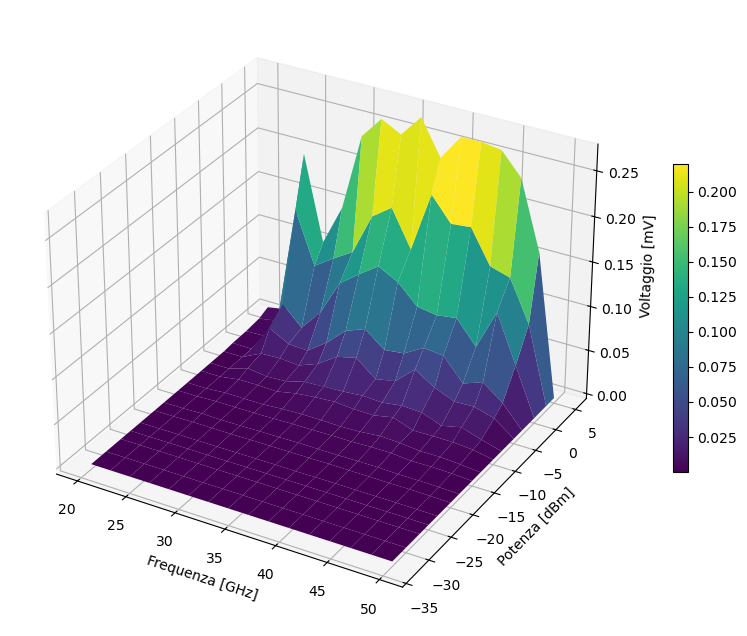

In [66]:

X_grid, Y_grid = np.meshgrid(freqs, powers, indexing='ij')


# 4. Plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Nota: X_grid è frequenza, Y_grid è potenza
surf = ax.plot_surface(X_grid, Y_grid, volts, cmap='viridis', antialiased=True)

ax.set_xlabel('Frequenza [GHz]')
ax.set_ylabel('Potenza [dBm]')
ax.set_zlabel('Voltaggio [mV]')
plt.colorbar(surf, ax=ax, shrink=0.5)
plt.show()


plt.show()

In [59]:
#savings data vector and matrix
np.save('powers.npy',powers)
np.save('freqs.npy',freqs)
np.save('volts.npy', volts)